# Three Ways to Mark Change

This native Julia companion preserves the public observations, training cutoff, feature timing, two-state Gaussian model, balanced logistic objective, and predeclared alarm and refit rules. Julia uses native likelihood and logistic solvers; numerical agreement is checked independently against the preserved Python suppliers. State labels are ordered by fitted variance, and displayed split positions retain the original zero-based boundary convention. Figures use the requested dark theme, and outputs are saved under `outputs/julia`.

## Comparing fixed thresholds with adaptive thresholds

Let \(x_t=100\log P_t\), so that \(\Delta x_t=r_t\) is the daily log return in percentage points. A symmetric cumulative sum keeps

$$
g_t^+=\max\{0,g_{t-1}^++\Delta x_t\},
\qquad
g_t^-=\min\{0,g_{t-1}^-+\Delta x_t\}.
$$

Here, \(g_t^+\) accumulates positive moves and \(g_t^-\) accumulates negative moves. An event is recorded when \(g_t^+>h_t\) or \(g_t^-<-h_t\), after which the crossed sum is reset. The fixed rule uses one threshold \(h\). The changing rule uses

$$
h_t=3\widehat\sigma_{t-1}^{(63)},
$$

where \(\widehat\sigma_{t-1}^{(63)}\) is the population standard deviation of the previous 63 daily returns. The threshold is therefore known before the return on date \(t\). Neither rule is presented as optimal.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("13_regime_adaptation");
using CSV, Printf
include(joinpath("..","support","BookEstimators.jl"))
include(joinpath("..","support","BookLogisticLBFGS.jl"))
include(joinpath("..","support","BookMarkovRegression.jl"))
using .BookMarkovRegression
using RiskLabAI.Backtest: prequential_adaptation
using RiskLabAI.Data: symmetric_cusum_filter,cusum_filter_events_dynamic_threshold
using RiskLabAI.Features: pelt_change_points
data_path = dataset_path("fred_nasdaq")
@assert isfile(data_path)
raw = CSV.read(data_path,DataFrame;missingstring=["","."])
data = sort(dropmissing(raw,:NASDAQCOM),:observation_date)
dates = DateTime.(Date.(data.observation_date))
prices = Float64.(data.NASDAQCOM)
daily_returns = vcat(NaN,100log.(prices[2:end]./prices[1:end-1]))
log_index = 100log.(prices)
violet = "#C084FC"
year_dates = DateTime.(Date(1995):Year(5):Date(2025))
year_ticks = (Dates.value.(year_dates),Dates.format.(year_dates,dateformat"yyyy"))
date_limits = Dates.value.((first(dates)-Day(90),last(dates)+Day(90)))
feature_names = ["Previous return (%)","Previous absolute return (%)","Trailing 5 day mean (%)","Trailing 21 day volatility (%)","Trailing 63 day volatility (%)"]
min_samples,window_size = 756,756

function table(frame,name,caption,label="tab:chapter14-"*replace(name,"_"=>"-"))
    save_table(frame,paths,name;caption,label)
    return nothing
end

function rolling_mean(values,window;minimum_count=window)
    return [index<minimum_count ? NaN : mean(values[max(1,index-window+1):index]) for index in eachindex(values)]
end

function prepare_sequential_data()
    positions = collect(65:length(prices))
    features = hcat(daily_returns[positions.-1],abs.(daily_returns[positions.-1]),[mean(daily_returns[index-5:index-1]) for index in positions],[std(daily_returns[index-21:index-1];corrected=false) for index in positions],[std(daily_returns[index-63:index-1];corrected=false) for index in positions])
    threshold = quantile(abs.(daily_returns[positions[1:min_samples]]),.8)
    targets = Int.(abs.(daily_returns[positions]).>threshold)
    frame = DataFrame(position=positions,date=dates[positions],daily_return=daily_returns[positions],target=targets)
    for (column,name) in enumerate(feature_names)
        frame[!,name] = features[:,column]
    end
    @assert all(isfinite,features)
    @assert allunique(Tuple.(eachrow(features)))
    return frame,features,targets,threshold
end

function run_policy(features,targets;policy=:adaptive,delta=.01,interval=252)
    positions = Dict(Tuple(row)=>index for (index,row) in enumerate(eachrow(features)))
    models = NamedTuple[]
    scores = fill(NaN,length(targets))
    function fitted(training_x,training_y)
        model = BookLogisticLBFGS.fit_logistic(training_x,training_y;C=1.,class_weight=:balanced,standardize=true,tol=1e-4,max_iter=1000)
        @assert model.converged
        push!(models,(first_position=positions[Tuple(training_x[1,:])],last_position=positions[Tuple(training_x[end,:])],model=model))
        return model
    end
    function predicted(model,row)
        scores[positions[Tuple(row[1,:])]] = only(BookEstimators.decision_function(model,row))
        return BookEstimators.predict(model,row)
    end
    if policy==:adaptive
        result = prequential_adaptation(features,Float64.(targets),nothing;fit_estimator=(_,x,y)->fitted(x,y),predict_estimator=predicted,clone_estimator=identity,loss_function=(actual,prediction)->Float64(actual!=prediction),window_size,min_samples,delta)
        return (;result...,models,scores)
    end
    predictions,losses = fill(NaN,length(targets)),fill(NaN,length(targets))
    refit_indices = [min_samples]
    model = fitted(features[1:min_samples,:],targets[1:min_samples])
    for index in min_samples+1:length(targets)
        predictions[index] = only(predicted(model,features[index:index,:]))
        losses[index] = Float64(predictions[index]!=targets[index])
        if policy==:periodic && (index-min_samples)%interval==0
            model = fitted(features[max(1,index-window_size+1):index,:],targets[max(1,index-window_size+1):index])
            push!(refit_indices,index)
        end
    end
    return (;predictions,losses,refit_indices,alarm_indices=Int[],models,scores)
end

function save_policy(result,name)
    observations = DataFrame(position=1:length(result.predictions),prediction=result.predictions,loss=result.losses,score=result.scores,refit=in.(1:length(result.predictions),Ref(result.refit_indices)),alarm=in.(1:length(result.predictions),Ref(result.alarm_indices)))
    save_data(observations,paths,name*"_observations")
    rows = NamedTuple[]
    for (number,record) in enumerate(result.models)
        model = record.model
        base = (fit=number,first_position=record.first_position,last_position=record.last_position,intercept=model.intercept,objective=model.objective,gradient_norm=model.gradient_norm,converged=model.converged,iterations=model.iterations)
        values = (; (Symbol("coefficient_",i)=>model.coefficients[i] for i in 1:5)...,(Symbol("center_",i)=>model.scaler.center[i] for i in 1:5)...,(Symbol("scale_",i)=>model.scaler.scale[i] for i in 1:5)...)
        push!(rows,merge(base,values))
    end
    save_data(DataFrame(rows),paths,name*"_fits")
    return nothing
end

function event_marks!(figure,event_dates,position,color)
    for date in event_dates
        plot!(figure,fill(Dates.value(date),2),[position-.28,position+.28];color,linewidth=.9,label=false)
    end
    return figure
end


event_marks! (generic function with 1 method)

Row,Setting,Fixed threshold rule,Changing threshold rule
,String,String,String
1,Input series,100 times log index level,100 times log index level
2,Threshold multiplier,3,3
3,Volatility sample,First 756 complete model rows,Previous 63 returns
4,Threshold timing,Frozen before evaluation,Known through the prior date
5,Reset,Crossed cumulative sum,Crossed cumulative sum


Row,Rule,Events,First event,Last event,Threshold description
,String,Int64,DateTime,DateTime,String
1,Fixed threshold,1599,1994-01-14T00:00:00,2025-12-19T00:00:00,2.6197512272034174
2,Changing threshold,986,1994-04-05T00:00:00,2025-12-23T00:00:00,Three times prior 63 day volatility


Row,Year,Fixed threshold events,Changing threshold events
,Int64,Int64,Int64
1,1994,23,23
2,1995,33,41
3,1996,34,30
4,1997,45,36
5,1998,62,37
6,1999,81,34
7,2000,121,41
8,2001,98,28
9,2002,97,31


Row,rule,position,date
,String,Int64,DateTime
1,Fixed threshold,1,1994-01-14T00:00:00
2,Fixed threshold,2,1994-02-04T00:00:00
3,Fixed threshold,3,1994-03-16T00:00:00
4,Fixed threshold,4,1994-03-28T00:00:00
5,Fixed threshold,5,1994-03-30T00:00:00
6,Fixed threshold,6,2025-11-20T00:00:00
7,Fixed threshold,7,2025-11-24T00:00:00
8,Fixed threshold,8,2025-12-04T00:00:00
9,Fixed threshold,9,2025-12-17T00:00:00


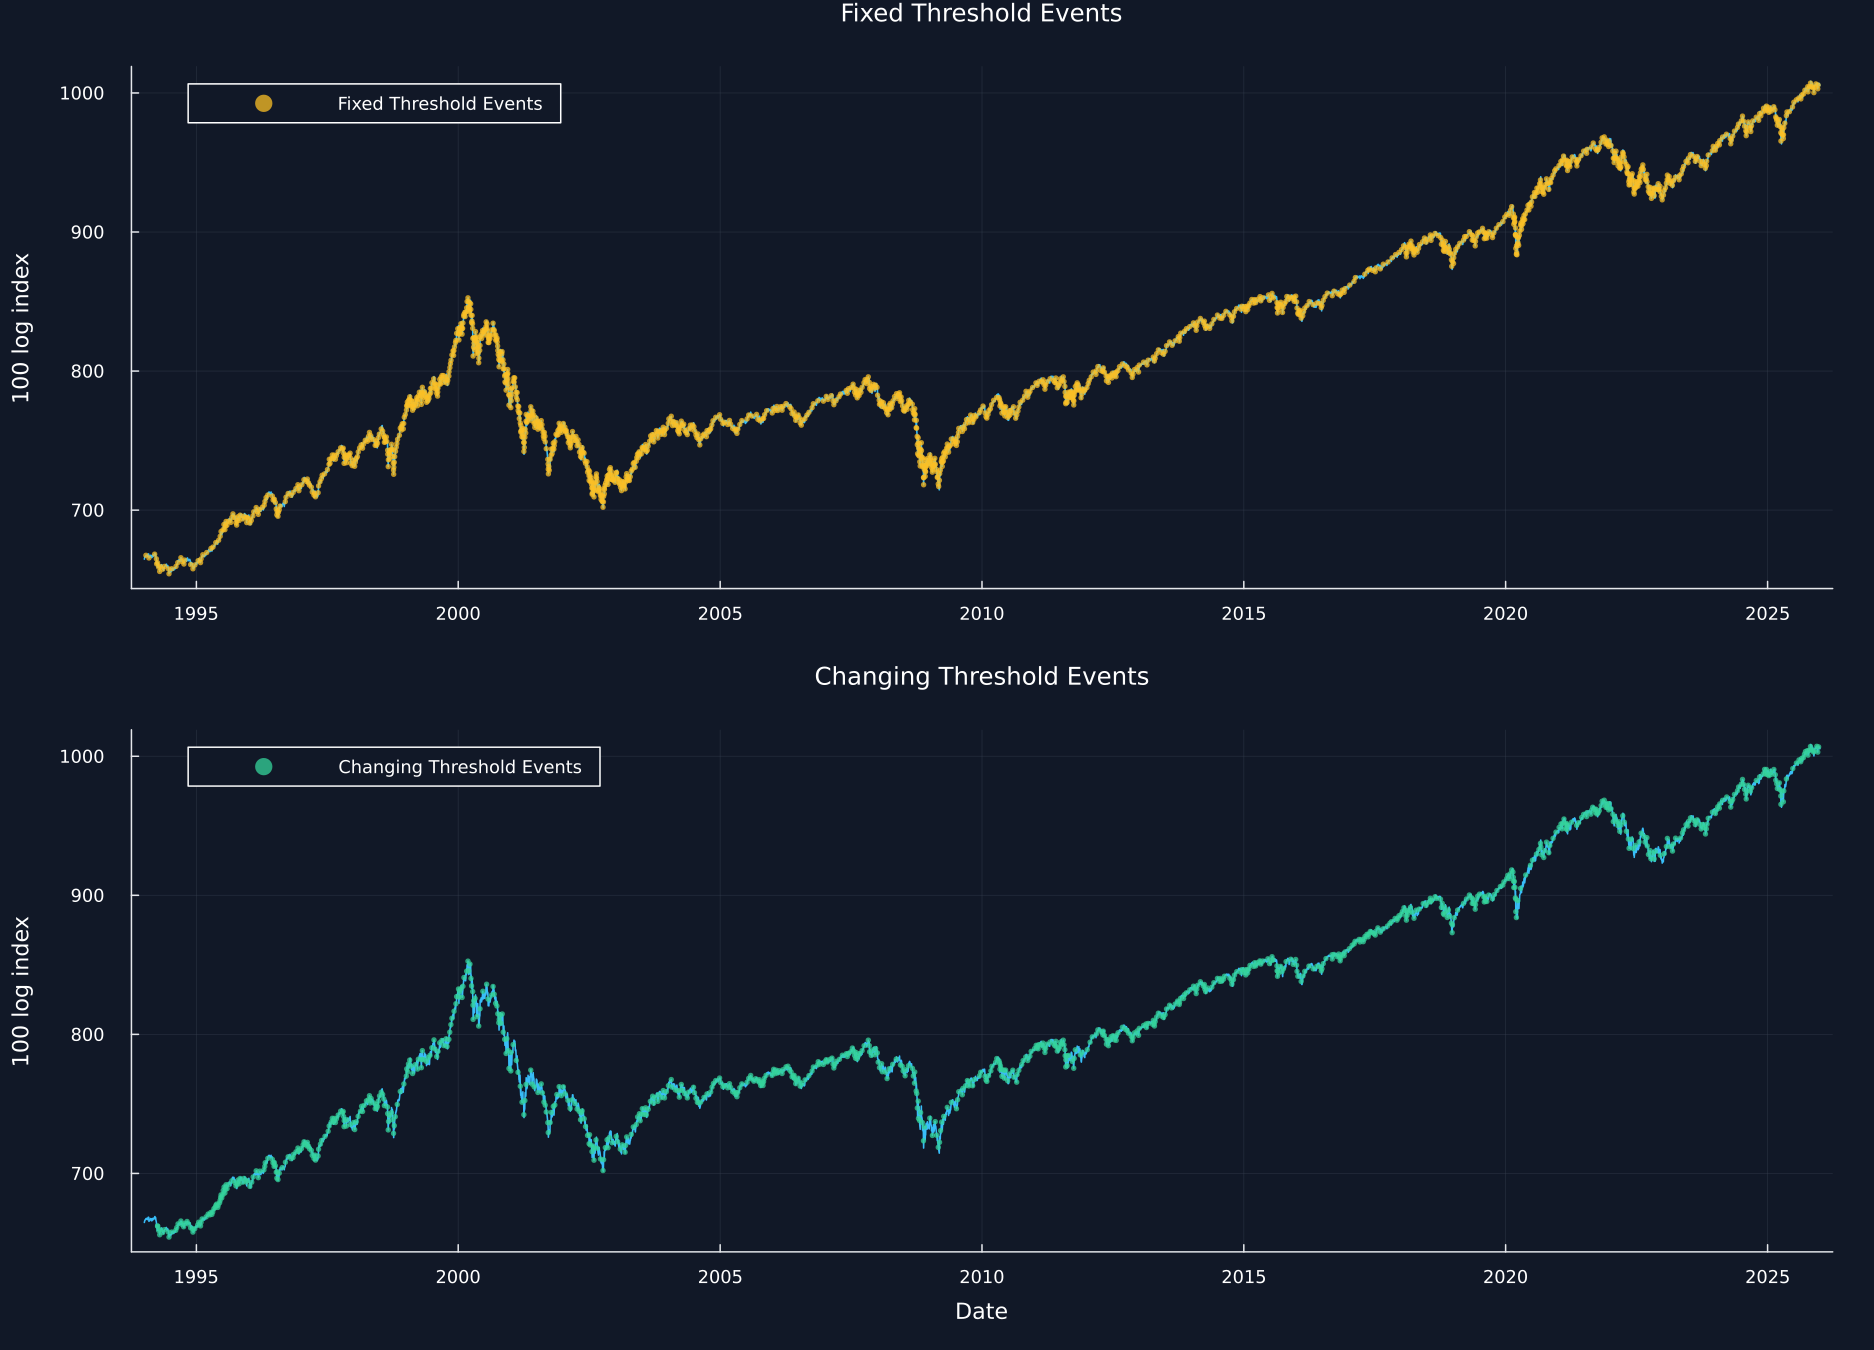

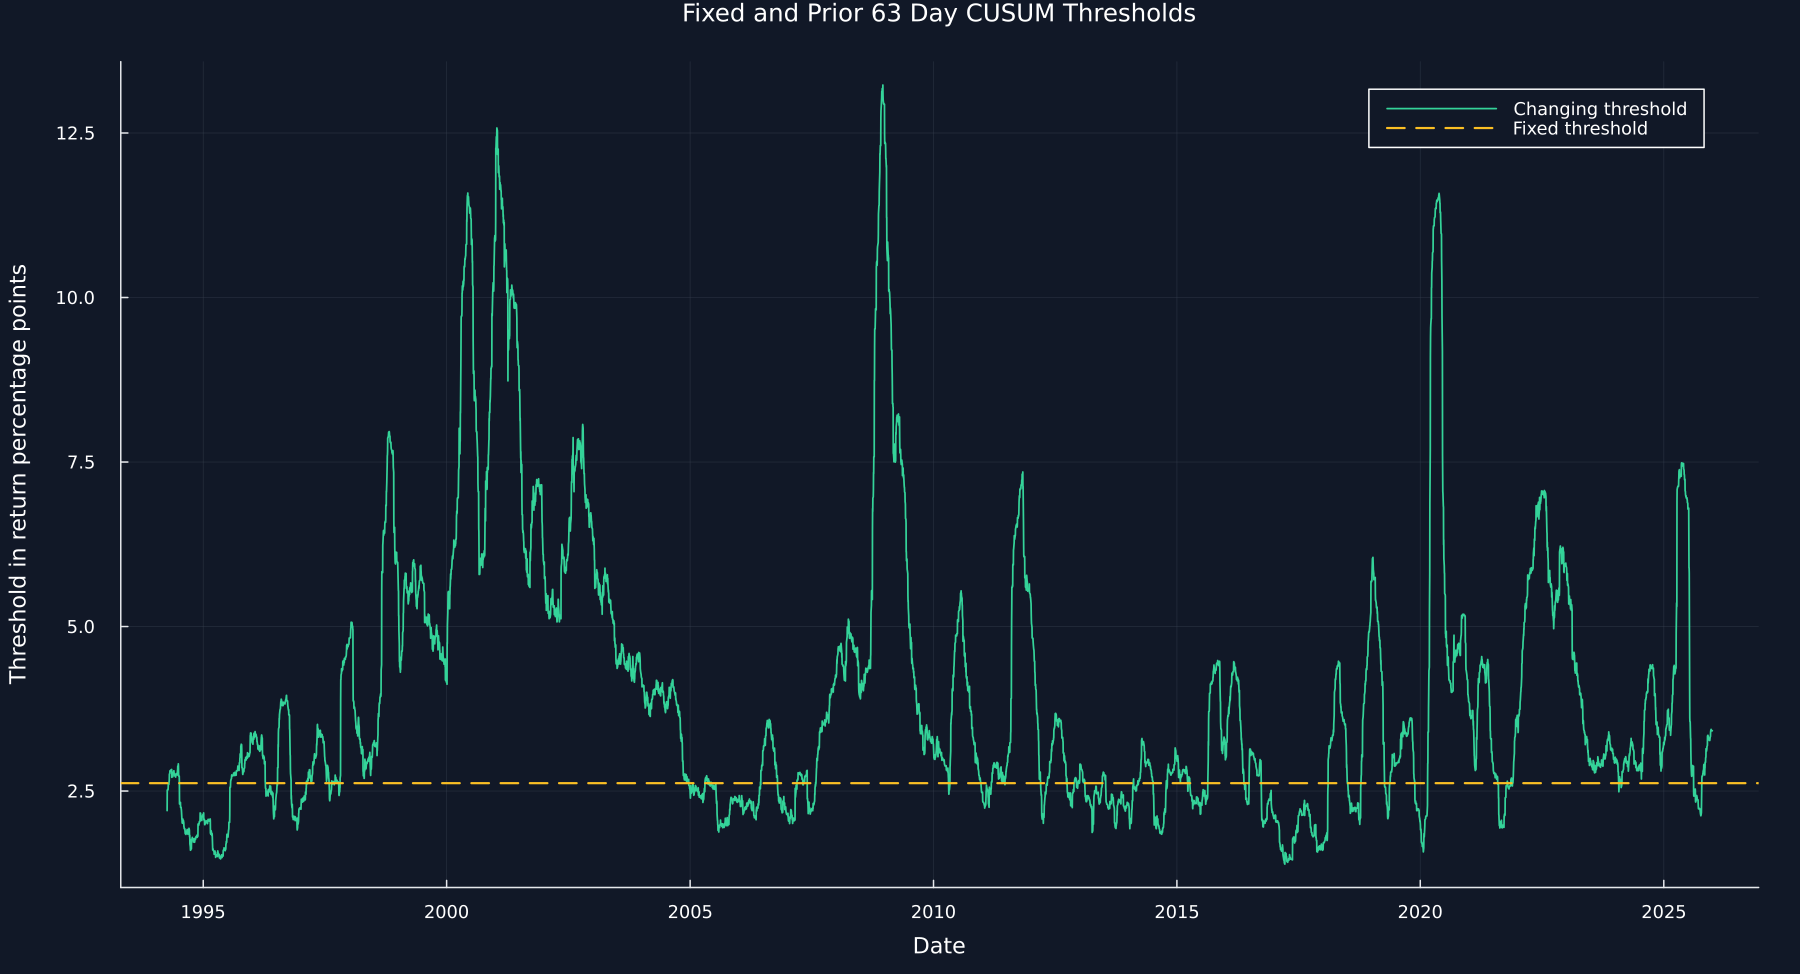

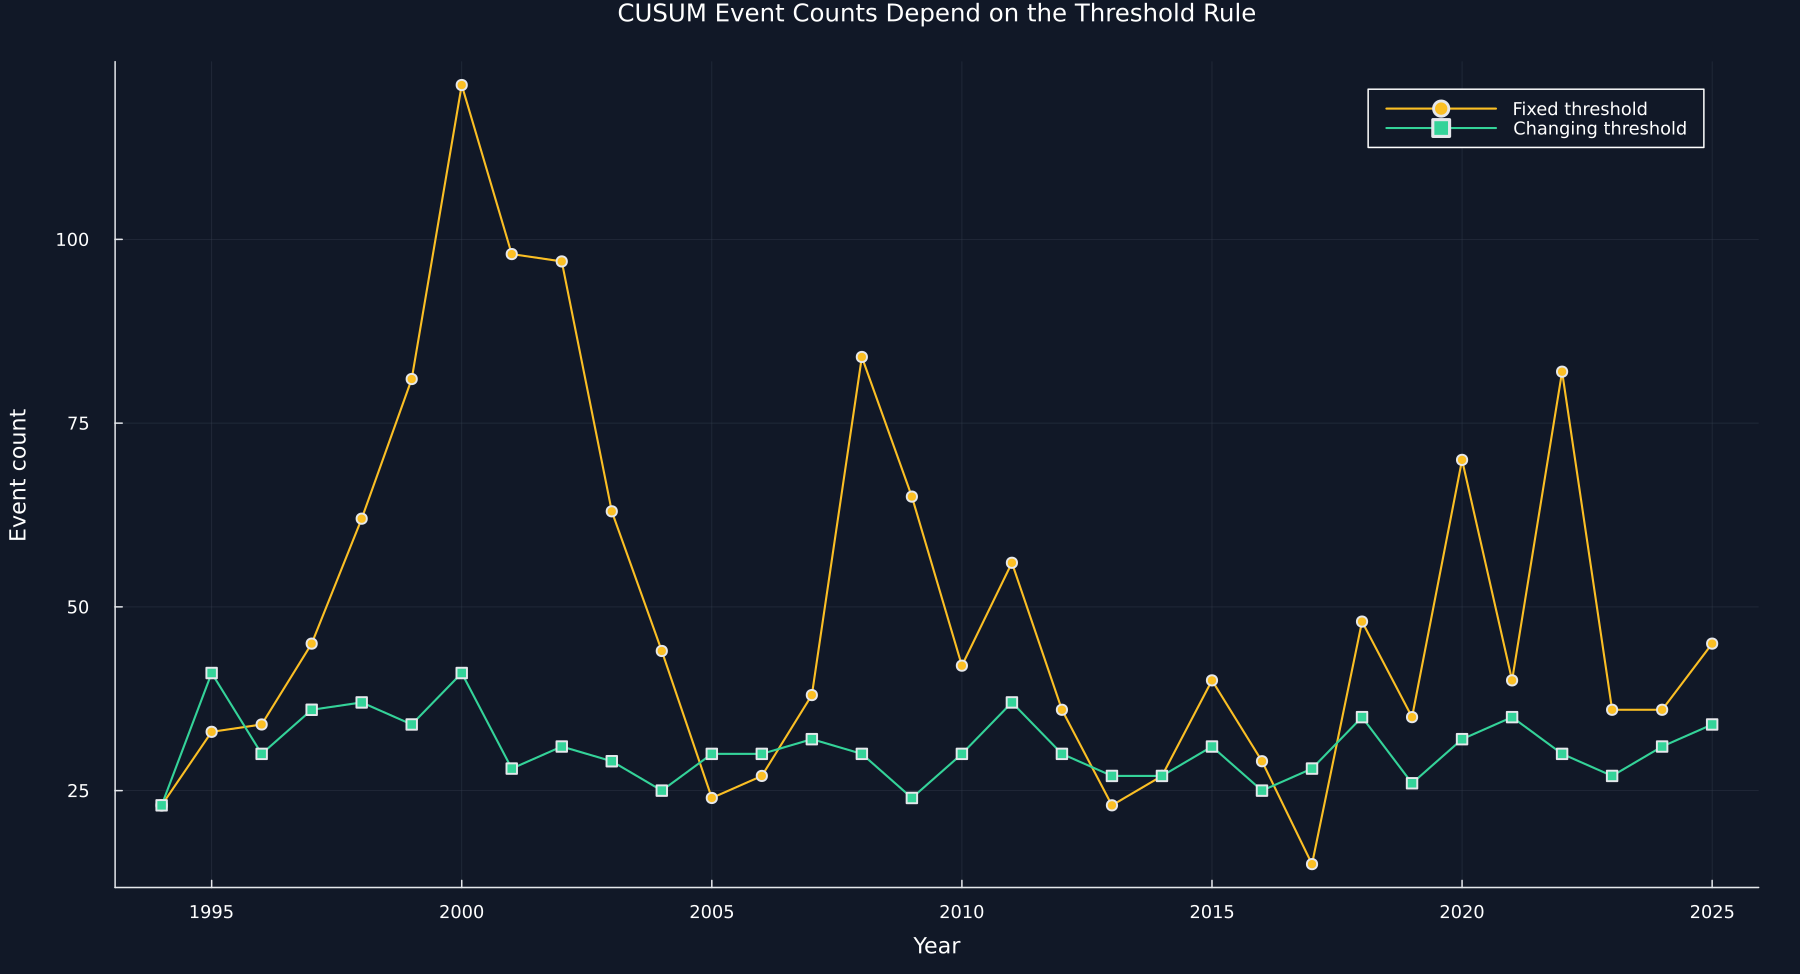

In [2]:
model_frame,features,targets,large_move_threshold = prepare_sequential_data()
save_data(model_frame,paths,"sequential_features");
fixed_threshold = 3std(model_frame.daily_return[1:min_samples];corrected=false)
changing_threshold = [index<65 ? NaN : 3std(daily_returns[index-63:index-1];corrected=false) for index in eachindex(dates)]
fixed_events = symmetric_cusum_filter(dates,log_index,fixed_threshold)
changing_events = cusum_filter_events_dynamic_threshold(dates,log_index,changing_threshold)
table(DataFrame("Setting"=>["Input series","Threshold multiplier","Volatility sample","Threshold timing","Reset"],"Fixed threshold rule"=>["100 times log index level","3","First 756 complete model rows","Frozen before evaluation","Crossed cumulative sum"],"Changing threshold rule"=>["100 times log index level","3","Previous 63 returns","Known through the prior date","Crossed cumulative sum"]),"cusum_settings","Settings for the fixed and changing CUSUM comparisons.")
table(DataFrame("Rule"=>["Fixed threshold","Changing threshold"],"Events"=>[length(fixed_events),length(changing_events)],"First event"=>[first(fixed_events),first(changing_events)],"Last event"=>[last(fixed_events),last(changing_events)],"Threshold description"=>[string(fixed_threshold),"Three times prior 63 day volatility"]),"cusum_summary","CUSUM event counts under the two predeclared threshold rules.")
years = collect(year(first(dates)):year(last(dates)))
year_counts = DataFrame("Year"=>years,"Fixed threshold events"=>[count(==(value),year.(fixed_events)) for value in years],"Changing threshold events"=>[count(==(value),year.(changing_events)) for value in years])
table(year_counts,"cusum_event_counts_by_year","CUSUM event counts by calendar year.","tab:chapter14-cusum-event-counts")
excerpts = DataFrame(rule=String[],position=Int[],date=DateTime[])
for (rule,events) in [("Fixed threshold",fixed_events),("Changing threshold",changing_events)]
    append!(excerpts,DataFrame(rule=fill(rule,10),position=1:10,date=vcat(events[1:5],events[end-4:end])))
end
table(excerpts,"cusum_event_dates_excerpt","First and last five dates from each CUSUM event list.","tab:chapter14-cusum-event-dates")
event_data = DataFrame(date=dates,log_index=log_index,fixed_event=in.(dates,Ref(fixed_events)),changing_event=in.(dates,Ref(changing_events)))
save_data(event_data,paths,"cusum_events");
panels = []
for (marked,color,name) in [(event_data.fixed_event,palette.amber,"Fixed Threshold Events"),(event_data.changing_event,palette.green,"Changing Threshold Events")]
    figure = plot(dates,log_index;color=palette.cyan,linewidth=1.05,label=false,ylabel="100 log index",title=name,legend=:topleft,xticks=year_ticks)
    scatter!(figure,dates[marked],log_index[marked];color,markersize=2,markerstrokewidth=0,alpha=.75,label=name)
    push!(panels,figure)
end
plot!(panels[2];xlabel="Date")
save_figure(plot(panels...;layout=(2,1),size=(1250,900),xlims=date_limits),paths,"cusum_events_log_price")
threshold_data = DataFrame(date=dates[65:end],changing_threshold=changing_threshold[65:end],fixed_threshold=fill(fixed_threshold,length(dates)-64))
save_data(threshold_data,paths,"cusum_dynamic_threshold");
p1 = plot(threshold_data.date,threshold_data.changing_threshold;color=palette.green,linewidth=1.15,label="Changing threshold",xlabel="Date",ylabel="Threshold in return percentage points",title="Fixed and Prior 63 Day CUSUM Thresholds",legend=:topright,xticks=year_ticks,size=(1200,650))
hline!(p1,[fixed_threshold];color=palette.amber,linestyle=:dash,linewidth=1.5,label="Fixed threshold")
save_figure(p1,paths,"cusum_dynamic_threshold")
save_data(year_counts,paths,"cusum_annual_event_counts");
p2 = plot(years,year_counts[!,2];color=palette.amber,marker=:circle,markersize=3.8,linewidth=1.4,label="Fixed threshold",xlabel="Year",ylabel="Event count",title="CUSUM Event Counts Depend on the Threshold Rule",legend=:topright,size=(1200,650))
plot!(p2,years,year_counts[!,3];color=palette.green,marker=:rect,markersize=3.5,linewidth=1.4,label="Changing threshold")
save_figure(p2,paths,"cusum_annual_event_counts")
@assert nrow(model_frame)==7991
@assert sum(year_counts[!,2])==length(fixed_events)
@assert sum(year_counts[!,3])==length(changing_events)


## ADWIN on Bounded Prediction Mistakes

After the 63 day feature warmup, the first 756 complete rows define the initial sample. Let \(c\) be the 80th percentile of the absolute returns in that sample. The target is

$$
y_t=\mathbf{1}\{|r_t|>c\}.
$$

Here, \(y_t=1\) marks a large absolute return under the frozen threshold \(c\), while \(y_t=0\) marks the other dates. The model available before observing \(y_t\) produces \(\widehat y_t\), and its bounded mistake is

$$
L_t=\mathbf{1}\{\widehat y_t\ne y_t\}.
$$

The loss \(L_t\) is zero for a correct class and one for an error. ADWIN receives this value only after the prediction has been made.

The original ADWIN construction considers a split \(W=W_0W_1\) of the current window. With \(n_0\) and \(n_1\) observations in the two parts, define

$$
m=\left(\frac{1}{n_0}+\frac{1}{n_1}\right)^{-1},
\qquad
\delta'=\frac{\delta}{n},
\qquad
\epsilon_{\mathrm{cut}}
=\sqrt{\frac{1}{2m}\log\frac{4}{\delta'}}.
$$

Here, \(n=n_0+n_1\), \(m\) is the harmonic combination of the subwindow sizes, \(\delta\) is the confidence parameter, and \(\epsilon_{\mathrm{cut}}\) is the stated cut threshold. A difference in subwindow means larger than the threshold is evidence of change. The notebook uses River's efficient ADWIN implementation with the fixed parameter \(\delta=0.01\).

Row,Feature,Definition,Latest information date
,String,String,String
1,Previous return,Return on date t minus 1,t minus 1
2,Previous absolute return,Absolute return on date t minus 1,t minus 1
3,Trailing 5 day mean,Mean of the five returns ending at t minus 1,t minus 1
4,Trailing 21 day volatility,Population standard deviation of 21 returns ending at t minus 1,t minus 1
5,Trailing 63 day volatility,Population standard deviation of 63 returns ending at t minus 1,t minus 1


Row,Quantity,Value
,String,String
1,Complete rows after feature warmup,7991
2,Initial rows,756
3,First initial date,1994-04-05
4,Last initial date,1997-04-01
5,Large move threshold (%),1.0330889152658003
6,Initial large move share,0.19973544973544974
7,Evaluation rows,7235
8,Evaluation large move share,0.3789910158949551


Row,Setting,Value
,String,String
1,Confidence parameter,0.01
2,Initial observations,756
3,Maximum refit window,756
4,Loss range,Zero to one
5,Estimator,Standardized logistic regression
6,Inverse regularization strength,1
7,Class weights,Balanced
8,Fixed seed,314159


Row,Alarm number,Date,Loss on alarm date
,Int64,DateTime,Float64
1,1,2000-07-18T00:00:00,0.0
2,2,2003-06-25T00:00:00,1.0
3,3,2005-04-06T00:00:00,0.0
4,4,2007-12-05T00:00:00,1.0
5,5,2009-01-28T00:00:00,0.0
6,6,2014-01-13T00:00:00,1.0
7,7,2016-04-27T00:00:00,1.0
8,8,2019-02-13T00:00:00,1.0
9,9,2023-03-08T00:00:00,1.0


Row,Check,Maximum absolute error,Tolerance,Result
,String,Float64,Float64,Bool
1,Predictions match when later rows are removed,0.0,0.0,true
2,Changing the current outcome leaves its own prediction unchanged,0.0,0.0,true
3,Every stored loss is zero or one,0.0,0.0,true
4,ADWIN replay gives the stored alarm dates,0.0,0.0,true
5,Alarm refits start with the next prediction,0.0,0.0,true


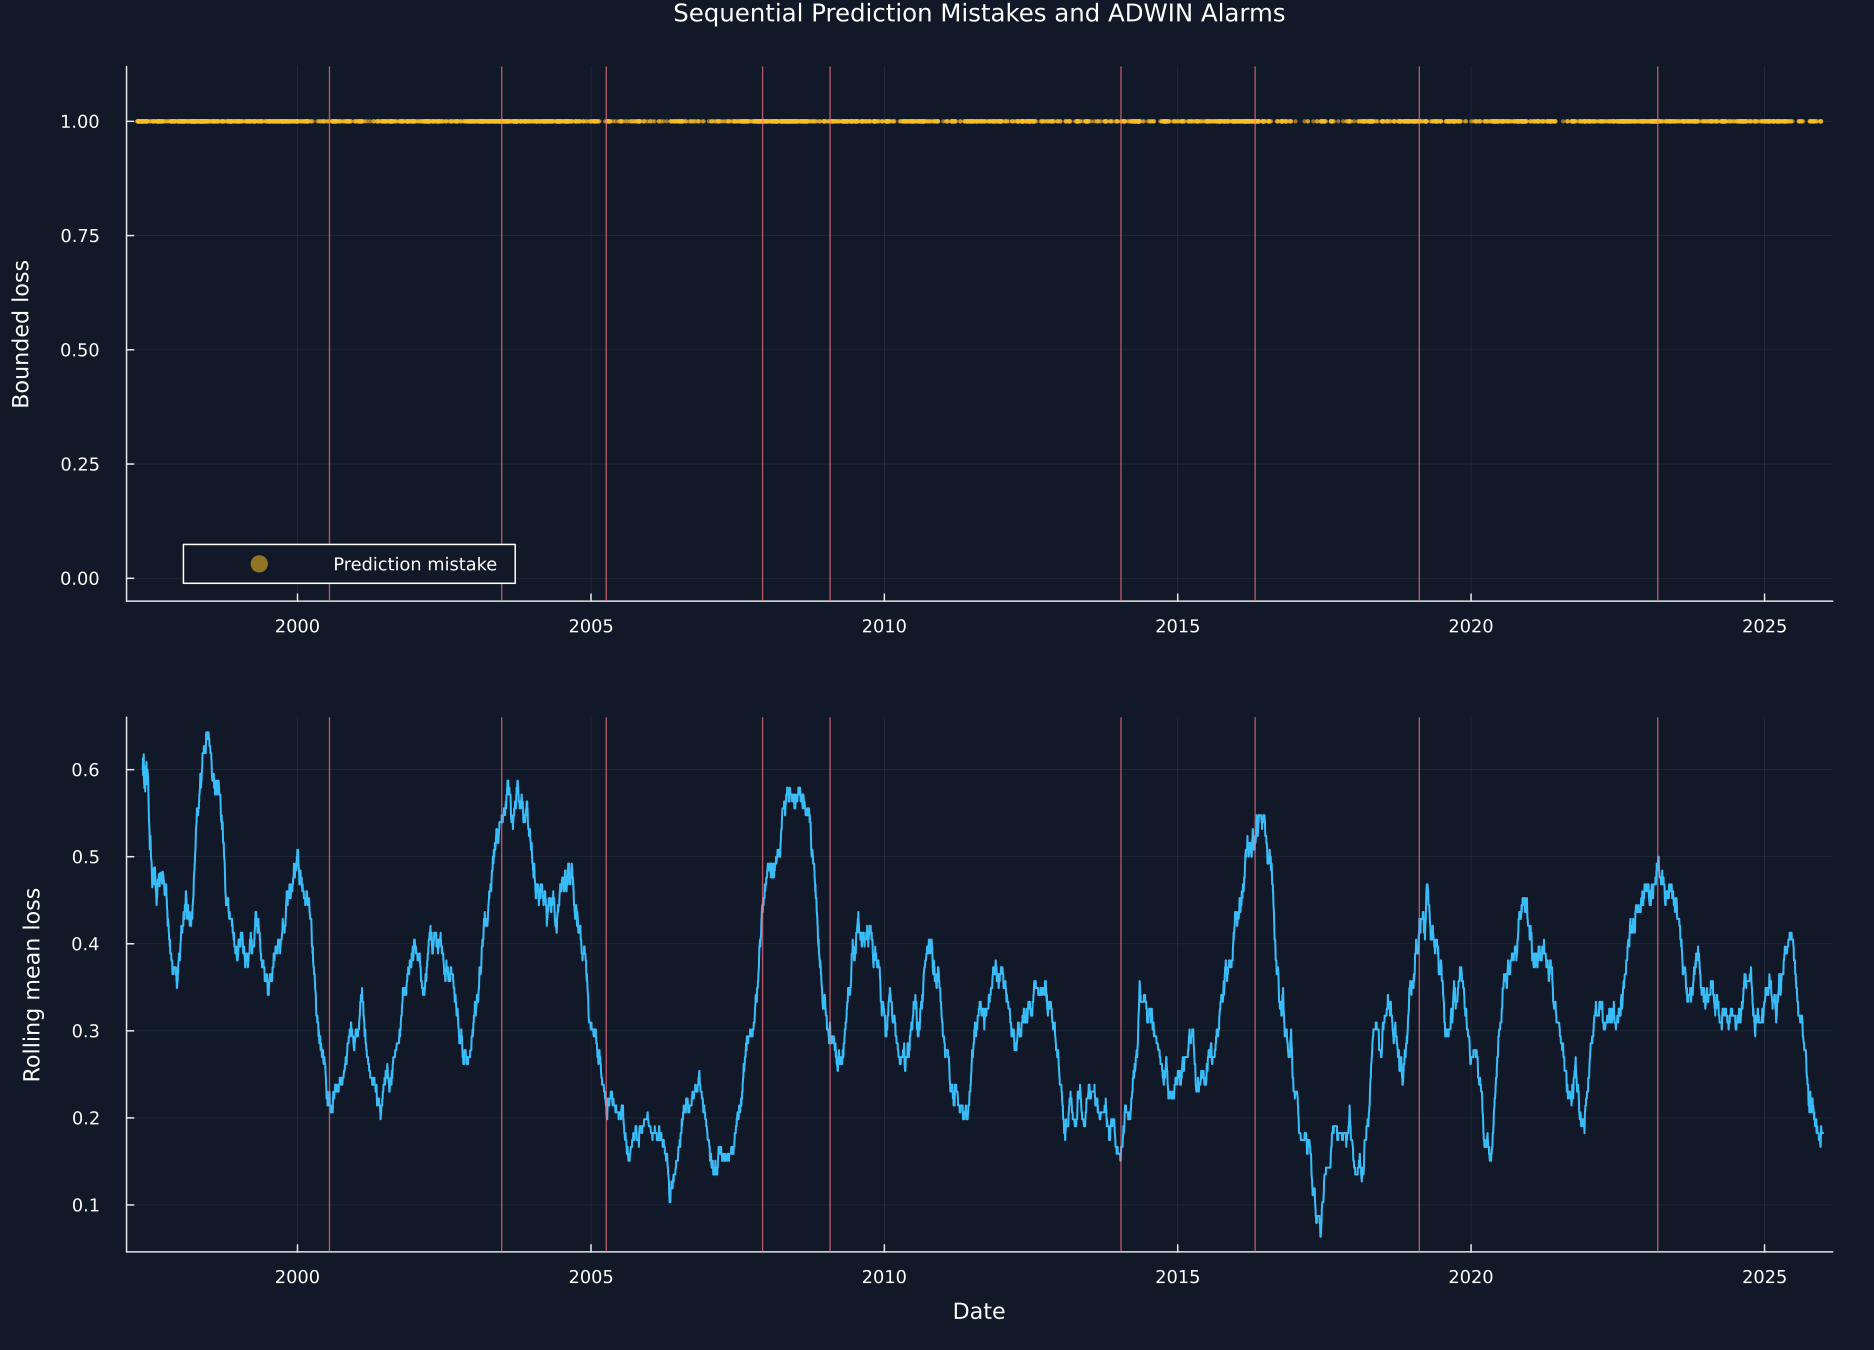

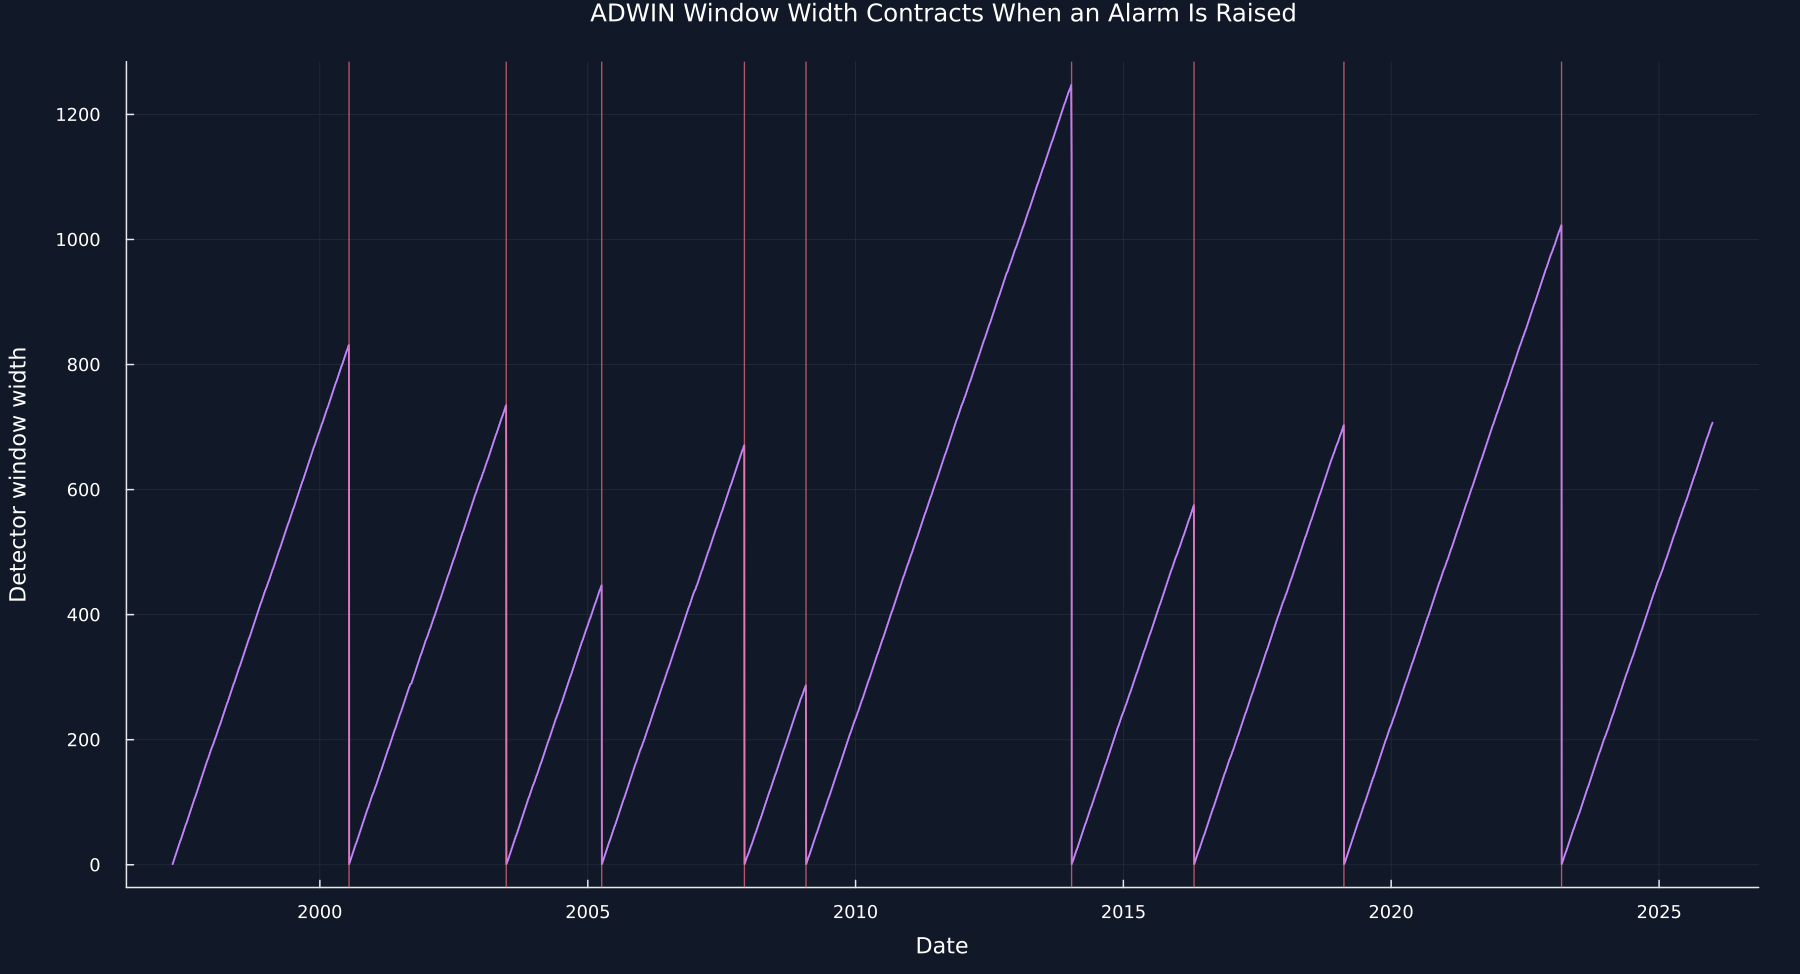

In [3]:
adaptive = run_policy(features,targets;delta=.01)
save_policy(adaptive,"adwin_default")
evaluation_dates = model_frame.date[min_samples+1:end]
evaluation_years = filter(date->first(evaluation_dates)<=date<=last(evaluation_dates),year_dates)
evaluation_ticks = (Dates.value.(evaluation_years),Dates.format.(evaluation_years,dateformat"yyyy"))
evaluation_losses = adaptive.losses[min_samples+1:end]
table(DataFrame("Feature" => ["Previous return", "Previous absolute return", "Trailing 5 day mean", "Trailing 21 day volatility", "Trailing 63 day volatility"],"Definition" => ["Return on date t minus 1", "Absolute return on date t minus 1", "Mean of the five returns ending at t minus 1", "Population standard deviation of 21 returns ending at t minus 1", "Population standard deviation of 63 returns ending at t minus 1"],"Latest information date" => ["t minus 1", "t minus 1", "t minus 1", "t minus 1", "t minus 1"]),"sequential_feature_definitions","Predictors and their information dates.","tab:chapter14-sequential-features")
table(DataFrame("Quantity"=>["Complete rows after feature warmup","Initial rows","First initial date","Last initial date","Large move threshold (%)","Initial large move share","Evaluation rows","Evaluation large move share"],"Value"=>[string(length(targets)),string(min_samples),string(Date(first(model_frame.date))),string(Date(model_frame.date[min_samples])),string(large_move_threshold),string(mean(targets[1:min_samples])),string(length(targets)-min_samples),string(mean(targets[min_samples+1:end]))]),"target_summary","Sequential target and frozen initial sample.")
table(DataFrame("Setting"=>["Confidence parameter","Initial observations","Maximum refit window","Loss range","Estimator","Inverse regularization strength","Class weights","Fixed seed"],"Value"=>["0.01",string(min_samples),"756","Zero to one","Standardized logistic regression","1","Balanced","314159"]),"adwin_settings","Fixed settings for the sequential ADWIN calculation.")
alarm_dates = model_frame.date[adaptive.alarm_indices]
table(DataFrame("Alarm number"=>collect(1:length(alarm_dates)),"Date"=>alarm_dates,"Loss on alarm date"=>adaptive.losses[adaptive.alarm_indices]),"adwin_alarm_dates","ADWIN alarm dates in the fixed public calculation.")
prefix_errors = Float64[]
for endpoint in [2500,5000]
    prefix = run_policy(features[1:endpoint,:],targets[1:endpoint];delta=.01)
    save_policy(prefix,"adwin_prefix_"*string(endpoint))
    push!(prefix_errors,maximum(abs.(adaptive.predictions[min_samples+1:endpoint].-prefix.predictions[min_samples+1:endpoint])))
end
altered_targets = copy(targets[1:2501])
altered_targets[2001] = 1-altered_targets[2001]
unaltered = run_policy(features[1:2501,:],targets[1:2501];delta=.01)
altered = run_policy(features[1:2501,:],altered_targets;delta=.01)
save_policy(unaltered,"adwin_unaltered_2501")
save_policy(altered,"adwin_altered_2501")
detector = RiskLabAI.Backtest._ADWINWindow(.01)
widths,replayed_alarm_indices = Int[],Int[]
detector_evidence = DataFrame(position=Int[],width=Int[],total=Float64[],centered_squares=Float64[],alarm=Bool[])
for index in min_samples+1:length(targets)
    alarm = RiskLabAI.Backtest._adwin_update!(detector,adaptive.losses[index])
    push!(widths,detector.width)
    alarm && push!(replayed_alarm_indices,index)
    push!(detector_evidence,(index,detector.width,detector.total,detector.centered_squares,alarm))
end
save_data(detector_evidence,paths,"adwin_detector_evidence");
current_error = abs(unaltered.predictions[2001]-altered.predictions[2001])
temporal_results = [maximum(prefix_errors)==0,current_error==0,all(in((0.,1.)),evaluation_losses),replayed_alarm_indices==adaptive.alarm_indices,adaptive.refit_indices[2:end]==adaptive.alarm_indices]
table(DataFrame("Check"=>["Predictions match when later rows are removed","Changing the current outcome leaves its own prediction unchanged","Every stored loss is zero or one","ADWIN replay gives the stored alarm dates","Alarm refits start with the next prediction"],"Maximum absolute error"=>[maximum(prefix_errors),current_error,0,0,0],"Tolerance"=>zeros(5),"Result"=>temporal_results),"temporal_order_checks","Checks that preserve prediction before observation and later-only refitting.")
@assert all(temporal_results)
@assert all(isnan,adaptive.predictions[1:min_samples])
loss_data = DataFrame(date=evaluation_dates,mistake=evaluation_losses,rolling_loss=rolling_mean(evaluation_losses,126;minimum_count=30),alarm=in.(evaluation_dates,Ref(alarm_dates)))
save_data(loss_data,paths,"adwin_loss_alarms");
mistakes = evaluation_losses.==1
p1 = scatter(evaluation_dates[mistakes],evaluation_losses[mistakes];color=palette.amber,markersize=1.6,markerstrokewidth=0,alpha=.55,label="Prediction mistake",ylims=(-.05,1.12),ylabel="Bounded loss",title="Sequential Prediction Mistakes and ADWIN Alarms",xticks=evaluation_ticks,legend=:bottomleft)
p2 = plot(evaluation_dates,loss_data.rolling_loss;color=palette.cyan,linewidth=1.35,label=false,ylabel="Rolling mean loss",xlabel="Date",xticks=evaluation_ticks)
for figure in [p1,p2],date in alarm_dates
    vline!(figure,[Dates.value(date)];color=palette.rose,linewidth=.9,alpha=.7,label=false)
end
evaluation_limits = Dates.value.((first(evaluation_dates)-Day(60),last(evaluation_dates)+Day(60)))
save_figure(plot(p1,p2;layout=(2,1),size=(1250,900),xlims=evaluation_limits),paths,"bounded_loss_adwin_alarms")
save_data(DataFrame(date=evaluation_dates,width=widths,alarm=loss_data.alarm),paths,"adwin_window_width");
p3 = plot(evaluation_dates,widths;color=violet,linewidth=1.25,label=false,xlabel="Date",ylabel="Detector window width",title="ADWIN Window Width Contracts When an Alarm Is Raised",xticks=evaluation_ticks,size=(1200,650))
for date in alarm_dates
    vline!(p3,[Dates.value(date)];color=palette.rose,linewidth=.9,alpha=.7,label=false)
end
save_figure(p3,paths,"adwin_window_width")


## Retrospective PELT Segments

Let the monthly loss observations be \(z_1,\ldots,z_T\). For ordered change points \(0=\tau_0<\tau_1<\cdots<\tau_m<\tau_{m+1}=T\), PELT solves

$$
\min_{m,\tau_1,\ldots,\tau_m}
\left\{
\sum_{j=0}^{m}
C\!\left(z_{\tau_j+1:\tau_{j+1}}\right)
+m\beta
\right\}.
$$

Here, \(C\) is the Gaussian segment cost, \(m\) is the number of interior change points, and \(\beta=3\log T\) is the penalty used in this notebook. Each segment must contain at least twelve months, and every monthly candidate date is considered. PELT sees the complete monthly loss series, so its dates are retrospective descriptions and never trigger a prediction or refit.

Row,Setting,Value
,String,String
1,Input,Monthly mean ADWIN policy loss
2,Months,345
3,Segment cost,Gaussian mean and variance cost
4,Penalty multiplier,3
5,Penalty,17.53063325109408
6,Minimum segment length,12
7,Candidate date step,1
8,Decision use,Retrospective only


Row,Change number,First month after change,Monthly position
,Int64,DateTime,Int64
1,1,2004-11-01T00:00:00,91
2,2,2007-07-01T00:00:00,123
3,3,2008-09-01T00:00:00,137


Row,Segment,First month,Last month,Months,Mean loss,Loss standard deviation
,Int64,DateTime,DateTime,Int64,Float64,Float64
1,1,1997-04-01T00:00:00,2004-10-01T00:00:00,91,0.404263,0.161671
2,2,2004-11-01T00:00:00,2007-06-01T00:00:00,32,0.18701,0.095341
3,3,2007-07-01T00:00:00,2008-08-01T00:00:00,14,0.510602,0.133343
4,4,2008-09-01T00:00:00,2025-12-01T00:00:00,208,0.308935,0.155619


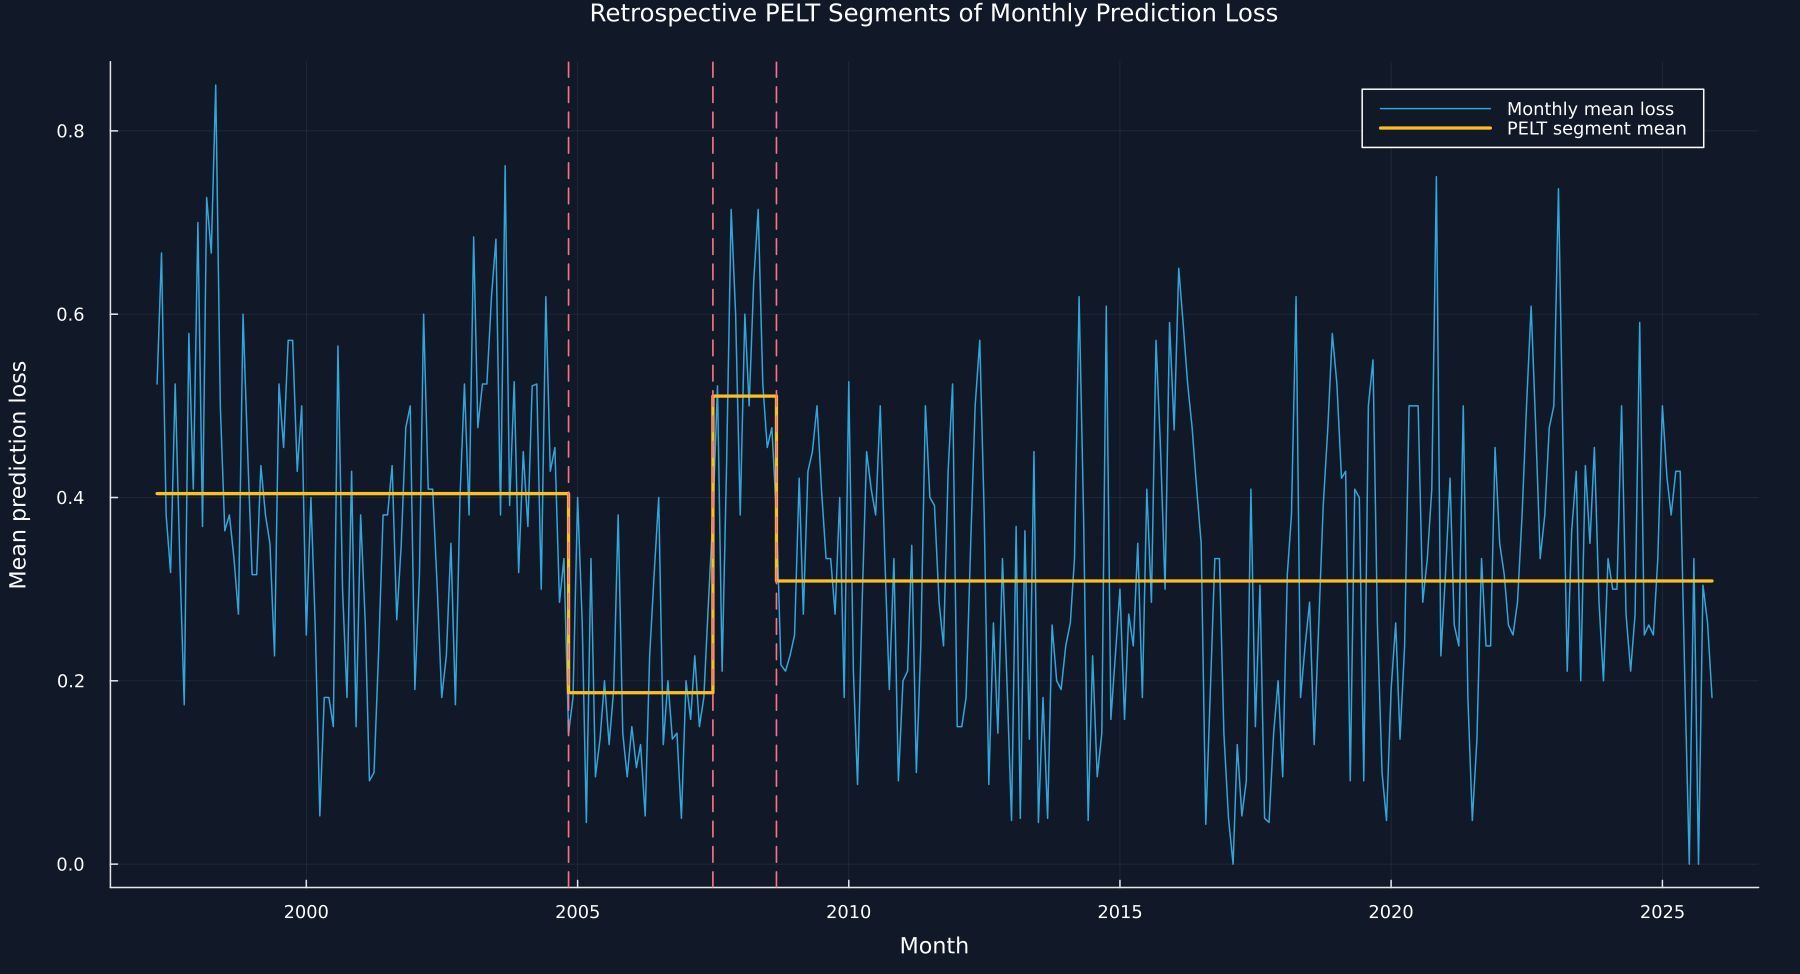

In [4]:
monthly_data = combine(groupby(DataFrame(month=firstdayofmonth.(Date.(evaluation_dates)),loss=evaluation_losses),:month;sort=true),:loss=>mean=>:monthly_loss)
monthly_data.month = DateTime.(monthly_data.month)
change_indices = pelt_change_points(monthly_data.monthly_loss;model="normal",penalty_multiplier=3.,min_size=12,jump=1)
boundaries = vcat(0,change_indices,nrow(monthly_data))
table(DataFrame("Setting"=>["Input","Months","Segment cost","Penalty multiplier","Penalty","Minimum segment length","Candidate date step","Decision use"],"Value"=>["Monthly mean ADWIN policy loss",string(nrow(monthly_data)),"Gaussian mean and variance cost","3",string(3log(nrow(monthly_data))),"12","1","Retrospective only"]),"pelt_settings","Fixed settings for the retrospective PELT comparison.")
change_dates = monthly_data.month[change_indices.+1]
table(DataFrame("Change number"=>collect(1:length(change_indices)),"First month after change"=>change_dates,"Monthly position"=>change_indices),"pelt_change_dates","Retrospective PELT change dates in monthly prediction loss.")
monthly_data.segment = zeros(Int,nrow(monthly_data))
monthly_data.segment_mean = zeros(nrow(monthly_data))
segments = NamedTuple[]
for (segment,(beginning,ending)) in enumerate(zip(boundaries[1:end-1],boundaries[2:end]))
    selected = beginning+1:ending
    values = monthly_data.monthly_loss[selected]
    monthly_data.segment[selected] .= segment
    monthly_data.segment_mean[selected] .= mean(values)
    push!(segments,(segment=segment,first_month=monthly_data.month[first(selected)],last_month=monthly_data.month[last(selected)],months=length(selected),mean_loss=mean(values),loss_std=std(values;corrected=false)))
end
segment_table = DataFrame(segments)
rename!(segment_table,["Segment","First month","Last month","Months","Mean loss","Loss standard deviation"])
table(segment_table,"pelt_segment_summary","Retrospective monthly loss segments returned by PELT.")
save_data(monthly_data,paths,"pelt_monthly_segments");
p1 = plot(monthly_data.month,monthly_data.monthly_loss;color=palette.cyan,linewidth=1,alpha=.85,label="Monthly mean loss",xlabel="Month",ylabel="Mean prediction loss",title="Retrospective PELT Segments of Monthly Prediction Loss",xticks=evaluation_ticks,legend=:topright,size=(1200,650))
plot!(p1,monthly_data.month,monthly_data.segment_mean;seriestype=:steppost,color=palette.amber,linewidth=2.2,label="PELT segment mean")
for date in change_dates
    vline!(p1,[Dates.value(date)];color=palette.rose,linestyle=:dash,linewidth=1.1,label=false)
end
save_figure(p1,paths,"monthly_pelt_segments")
@assert sum(segment_table.Months)==nrow(monthly_data)
@assert all(segment_table.Months.>=12)


## Why the Dates Differ

The three calculations mark different objects. CUSUM accumulates moves in the public log price. ADWIN monitors the bounded sequence of prediction mistakes and issues an online alarm after each observed loss. PELT partitions the completed monthly loss history. Agreement is possible, but equality of dates is not expected and is not a requirement for validity.

Row,Method,Input,Timing,Default event count,Role
,String,String,String,Int64,String
1,Fixed threshold CUSUM,Daily log price moves,Online event,1599,Marks cumulative price moves
2,Changing threshold CUSUM,Daily log price moves,Online event,986,Uses prior 63 day volatility
3,ADWIN,Daily prediction mistakes,Online alarm,9,May trigger a later refit
4,PELT,Monthly mean prediction loss,Retrospective segment,3,Describes the completed loss path


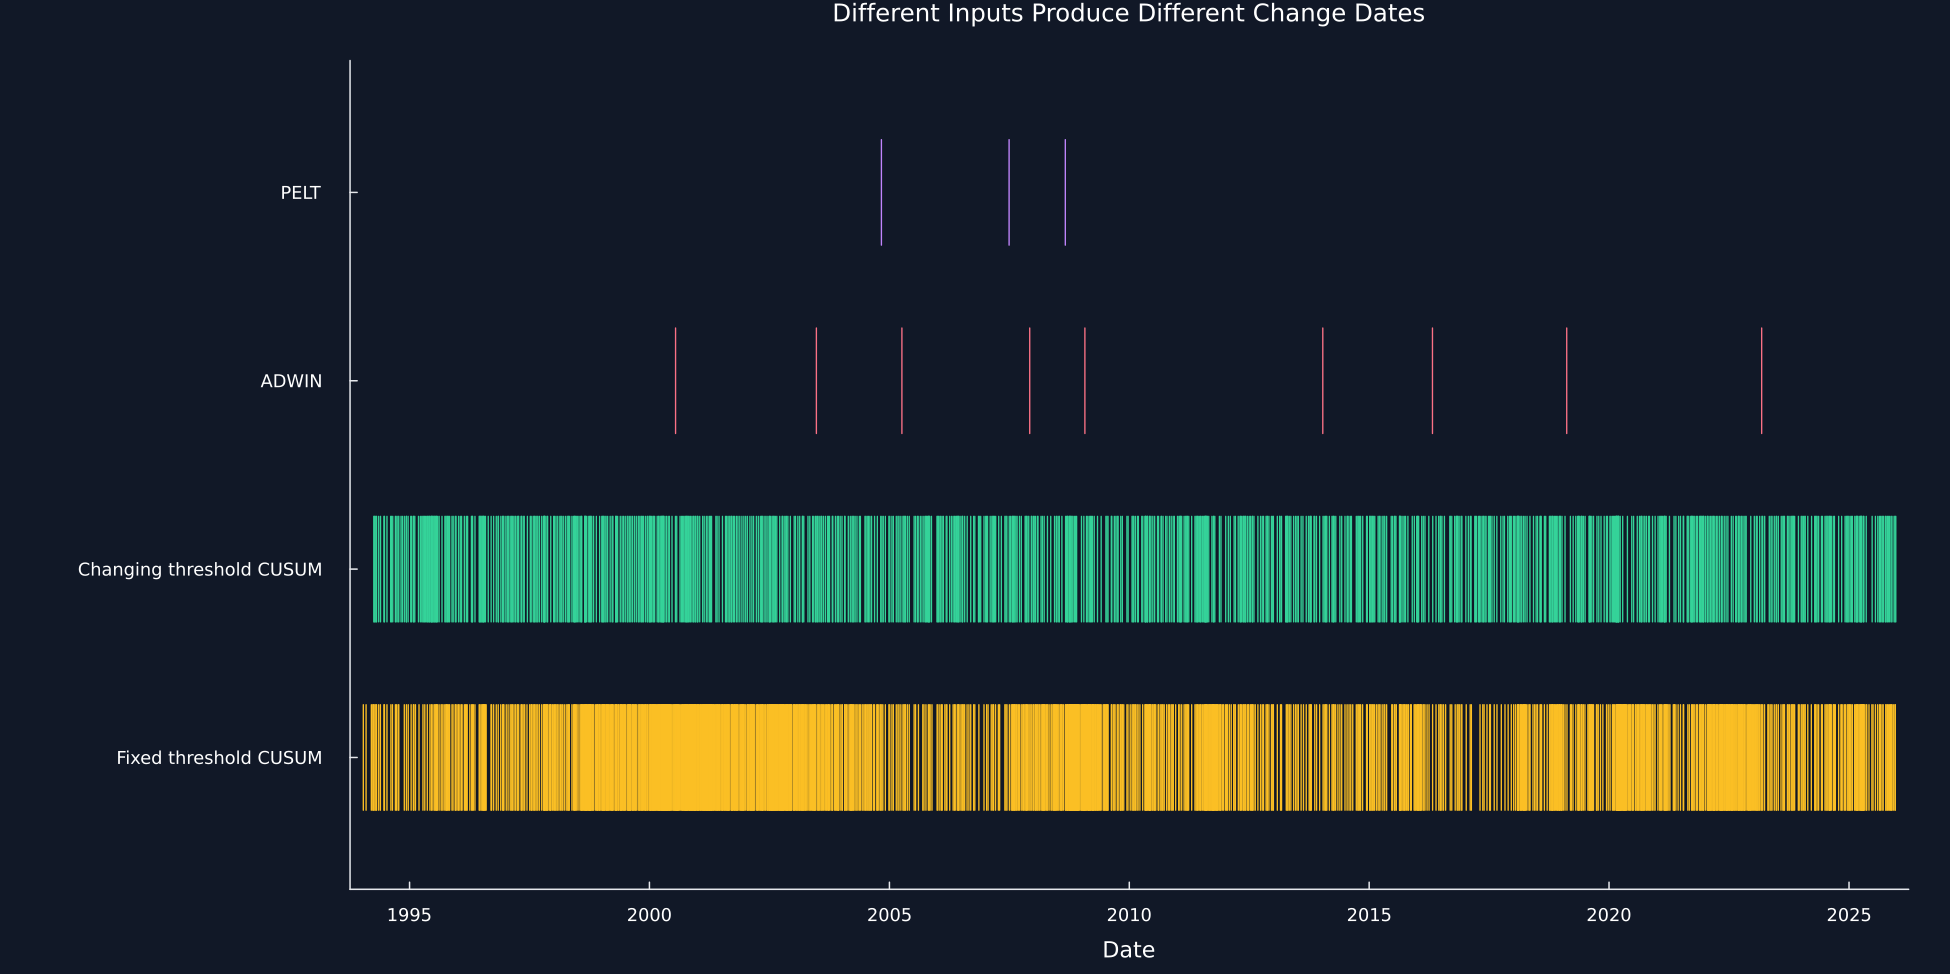

In [5]:
method_names = ["Fixed threshold CUSUM","Changing threshold CUSUM","ADWIN","PELT"]
event_collections = [fixed_events,changing_events,alarm_dates,change_dates]
table(DataFrame("Method"=>method_names,"Input"=>["Daily log price moves","Daily log price moves","Daily prediction mistakes","Monthly mean prediction loss"],"Timing"=>["Online event","Online event","Online alarm","Retrospective segment"],"Default event count"=>length.(event_collections),"Role"=>["Marks cumulative price moves","Uses prior 63 day volatility","May trigger a later refit","Describes the completed loss path"]),"detector_method_comparison","Inputs, timing, and roles of the three change calculations.","tab:chapter14-detector-comparison")
timeline = DataFrame(date=DateTime[],method=String[])
p1 = plot(;xlabel="Date",title="Different Inputs Produce Different Change Dates",yticks=(0:3,method_names),ylims=(-.7,3.7),xlims=date_limits,xticks=year_ticks,grid=false,size=(1300,650),left_margin=12Plots.mm)
for (position,(name,events,color)) in enumerate(zip(method_names,event_collections,[palette.amber,palette.green,palette.rose,violet]))
    append!(timeline,DataFrame(date=events,method=fill(name,length(events))))
    event_marks!(p1,events,position-1,color)
end
save_data(timeline,paths,"detector_timeline");
save_figure(p1,paths,"detector_timeline")
@assert nrow(timeline)==sum(length,event_collections)
@assert all(0 .<= evaluation_losses .<= 1)
